In [1]:
import numpy as np
import argparse
import os
import importlib

The history saving thread hit an unexpected error (OperationalError('attempt to write a readonly database')).History will not be written to the database.


In [2]:
import simulate_CCE_Li_radii

--------------------------------
CCE simulation
--------------------------------
seed = 1
--------------------------------


In [3]:
importlib.reload(simulate_CCE_Li_radii)

--------------------------------
CCE simulation
--------------------------------
seed = 1
--------------------------------


<module 'simulate_CCE_Li_radii' from '/global/u2/r/ritaferi/CTM/CCE_study/simulate_CCE_Li_radii.py'>

In [24]:
my_args = argparse.Namespace(        
            seed=123,        
            N_charges=50,        
            N_repeat=50,        
            alpha=1.6e-11,     
            FCCD = 0.085,   
            sigma_R = 0.001,
            N_sat = 1e14,
            T_ann=623,        
            t_ann=18*60,        
            output="library"
        )

In [25]:
params = simulate_CCE_Li_radii.update_parameters(my_args)

In [26]:
# litio
cells, saturation_depth, px, py, pz, particles_R, lithium_distribution = simulate_CCE_Li_radii.generate_lithium(params)

print("Numero Li:", len(px))
print("Profondità saturazione:", saturation_depth*10, "mm")


Calculating Li concentration: 100%|██████████| 66/66 [00:00<00:00, 205970.29it/s]


0.001 um



Generating Li agglomerates: 100%|██████████| 66/66 [00:00<00:00, 4775.05it/s]


Total theoretical primary Li (R=20 um) = 1240
Total theoretical agglomerates = 388
Total theoretical remaining 20 um particles = 69
Total accepted agglomerates = 388
Total accepted remaining 20 um particles = 69
Total accepted Li particles = 457
Numero Li: 457
Profondità saturazione: 0.66 mm


In [23]:
# litio
cells, saturation_depth, px, py, pz, particles_R, lithium_distribution = simulate_CCE_Li_radii.generate_lithium(params)

print("Numero Li:", len(px))
print("Profondità saturazione:", saturation_depth*10, "mm")


Calculating Li concentration: 100%|██████████| 66/66 [00:00<00:00, 136906.07it/s]


0.001 um



Generating Li agglomerates: 100%|██████████| 66/66 [00:00<00:00, 5272.34it/s]


Total theoretical primary Li (R=20 um) = 1205
Total theoretical agglomerates = 396
Total theoretical remaining 20 um particles = 46
Total accepted agglomerates = 396
Total accepted remaining 20 um particles = 46
Total accepted Li particles = 442
Numero Li: 442
Profondità saturazione: 0.66 mm


In [27]:
x, CCE_matrix, CCE_mean, CCE_std = simulate_CCE_Li_radii.simulate_CCE(
    cells,
    saturation_depth,
    px,
    py,
    pz,
    particles_R, 
    my_args
)


Starting CCE simulation...



CCE depth: 100%|██████████| 20/20 [00:23<00:00,  1.15s/it]


In [28]:
'''
import os

os.makedirs("library", exist_ok=True)


np.savez(
    "library/curve_000001.npz",

    x=x,

    CCE=CCE_matrix,

    CCE_mean=CCE_mean,

    CCE_std=CCE_std,

    particle_x=px,

    particle_y=py,

    particle_z=pz,

    seed=1,

    N_charges=250,

    N_repeat=250,

    alpha=simulate_CCE.alpha,

    T_ann=simulate_CCE.T_ann,

    t_ann=simulate_CCE.t_ann,

    saturation_depth=saturation_depth
)


print("creato library/curve_000001.npz")'''

'\nimport os\n\nos.makedirs("library", exist_ok=True)\n\n\nnp.savez(\n    "library/curve_000001.npz",\n\n    x=x,\n\n    CCE=CCE_matrix,\n\n    CCE_mean=CCE_mean,\n\n    CCE_std=CCE_std,\n\n    particle_x=px,\n\n    particle_y=py,\n\n    particle_z=pz,\n\n    seed=1,\n\n    N_charges=250,\n\n    N_repeat=250,\n\n    alpha=simulate_CCE.alpha,\n\n    T_ann=simulate_CCE.T_ann,\n\n    t_ann=simulate_CCE.t_ann,\n\n    saturation_depth=saturation_depth\n)\n\n\nprint("creato library/curve_000001.npz")'

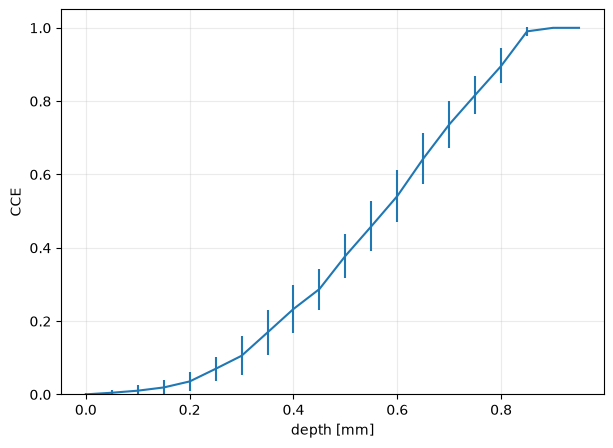

In [29]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7,5))

plt.errorbar(
    x*10,
    CCE_mean,
    yerr = CCE_std)

plt.xlabel("depth [mm]")
plt.ylabel("CCE")

plt.ylim(0,1.05)

plt.grid(alpha = 0.25)

plt.show()

In [30]:
CCE_matrix.shape

(20, 50)

In [31]:
CCE_matrix.shape[1]

50

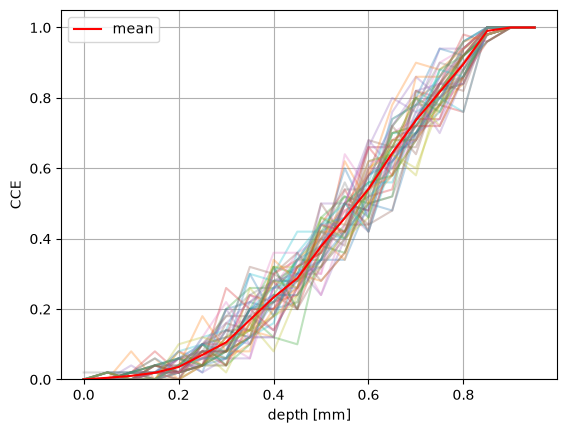

In [32]:


for j in range(CCE_matrix.shape[1]):

    plt.plot(
        x*10,
        CCE_matrix[:,j],
        alpha=0.3
    )


# media
plt.plot(
    x*10,
    CCE_mean,
    linewidth=1.5,
    label="mean",
    color = 'red'
)


plt.xlabel("depth [mm]")
plt.ylabel("CCE")

plt.ylim(0,1.05)

plt.grid()

plt.legend()

plt.show()

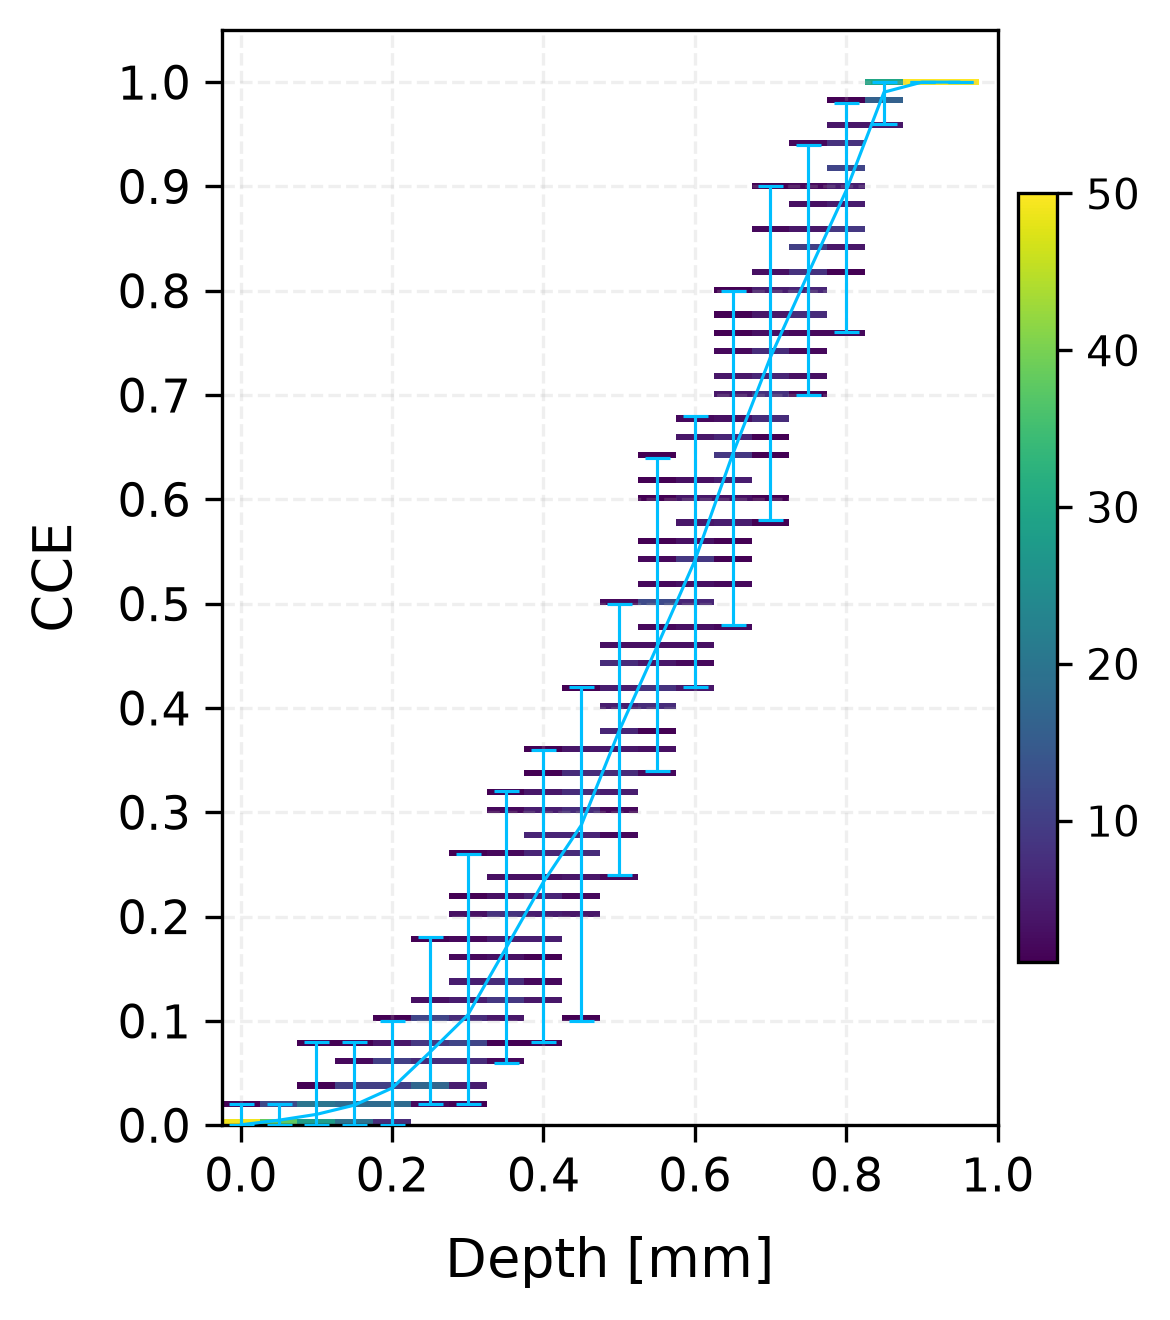

In [33]:
# ============================================================
# CCE DENSITY MAP — INFERNO STYLE
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize


# ============================================================
# COLORS — INFERNO PALETTE
# ============================================================

c_mean = "#FFD27F"       # warm light orange
c_sd = "#FF9F4A"         # orange
c_minmax = "#6D1F3A"     # dark reddish-purple
c_rdr = "#FFF3D6"        # warm white


# ============================================================
# X COORDINATES
# ============================================================

# x is assumed to be in cm
# convert to micrometres

x_plot = x * 10


# ============================================================
# BIN EDGES
# ============================================================

x_edges = np.empty(
    len(x_plot) + 1
)

x_edges[1:-1] = (
    x_plot[:-1] +
    x_plot[1:]
) / 2

dx_plot = (
    x_plot[1] -
    x_plot[0]
)

x_edges[0] = (
    x_plot[0] -
    dx_plot / 2
)

x_edges[-1] = (
    x_plot[-1] +
    dx_plot / 2
)


# ============================================================
# HISTOGRAM DATA
# ============================================================

X = np.repeat(
    x_plot,
    CCE_matrix.shape[1]
)

Y = CCE_matrix.flatten()


# ============================================================
# FIGURE
# ============================================================

fig, ax = plt.subplots(
    figsize=(4,4.5),
    dpi=300
)


# ============================================================
# CCE DENSITY MAP
# ============================================================

h = ax.hist2d(
    X,
    Y,
    bins=[
        x_edges,
        np.linspace(0, 1.05, 180)
    ],
    cmap="viridis",
    cmin=1
)


# ============================================================
# STATISTICS
# ============================================================

CCE_min = np.min(
    CCE_matrix,
    axis=1
)

CCE_max = np.max(
    CCE_matrix,
    axis=1
)


# ============================================================
# MIN–MAX
# ============================================================

ax.errorbar(
    x_plot,
    CCE_mean,
    yerr=[
        CCE_mean - CCE_min,
        CCE_max - CCE_mean
    ],
    color='deepskyblue',
    linewidth=0.75,
    capsize=3,
    capthick=0.75,
    elinewidth=0.75,
    fmt="none",
    label="Min–max",
    zorder=3
)

# ============================================================
# MEAN
# ============================================================

ax.plot(
    x_plot,
    CCE_mean,
    color='deepskyblue',
    linewidth=0.75,
    solid_capstyle="round",
    label="Mean",
    zorder=6
)


# ============================================================
# AXIS LIMITS
# ============================================================

ax.set_xlim(
    x_edges[0],
    x_edges[-1]
)

ax.set_ylim(
    0,
    1.05
)


# ============================================================
# LABELS
# ============================================================

ax.set_xlabel(
    "Depth [mm]",
    fontsize=13,
    labelpad=8
)

ax.set_ylabel(
    "CCE",
    fontsize=13,
    labelpad=8
)


# ============================================================
# TICKS
# ============================================================

ax.tick_params(
    axis="both",
    which="major",
    labelsize=11,
    length=4,
    width=0.8
)

ax.set_yticks(
    np.arange(
        0,
        1.01,
        0.1
    )
)
ax.set_xticks(
    np.arange(
        0,
        1.1,
        0.2
    )
)


# ============================================================
# COLORBAR
# ============================================================

cbar = fig.colorbar(
    h[3],
    ax=ax,
    pad=0.025,
    fraction=0.046
)

plt.grid(alpha = 0.2,
        ls = '--')
# ============================================================
# LAYOUT
# ============================================================

fig.tight_layout()

plt.savefig("plot/CCE_distr.png")

In [34]:
18*60

1080

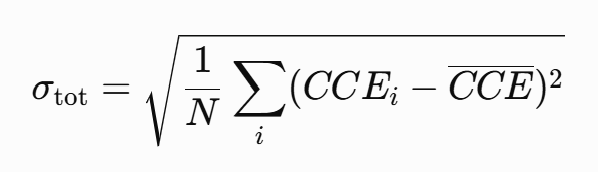

In [35]:
CCE_matrix.shape

(20, 50)

NameError: name 'legend_handles' is not defined

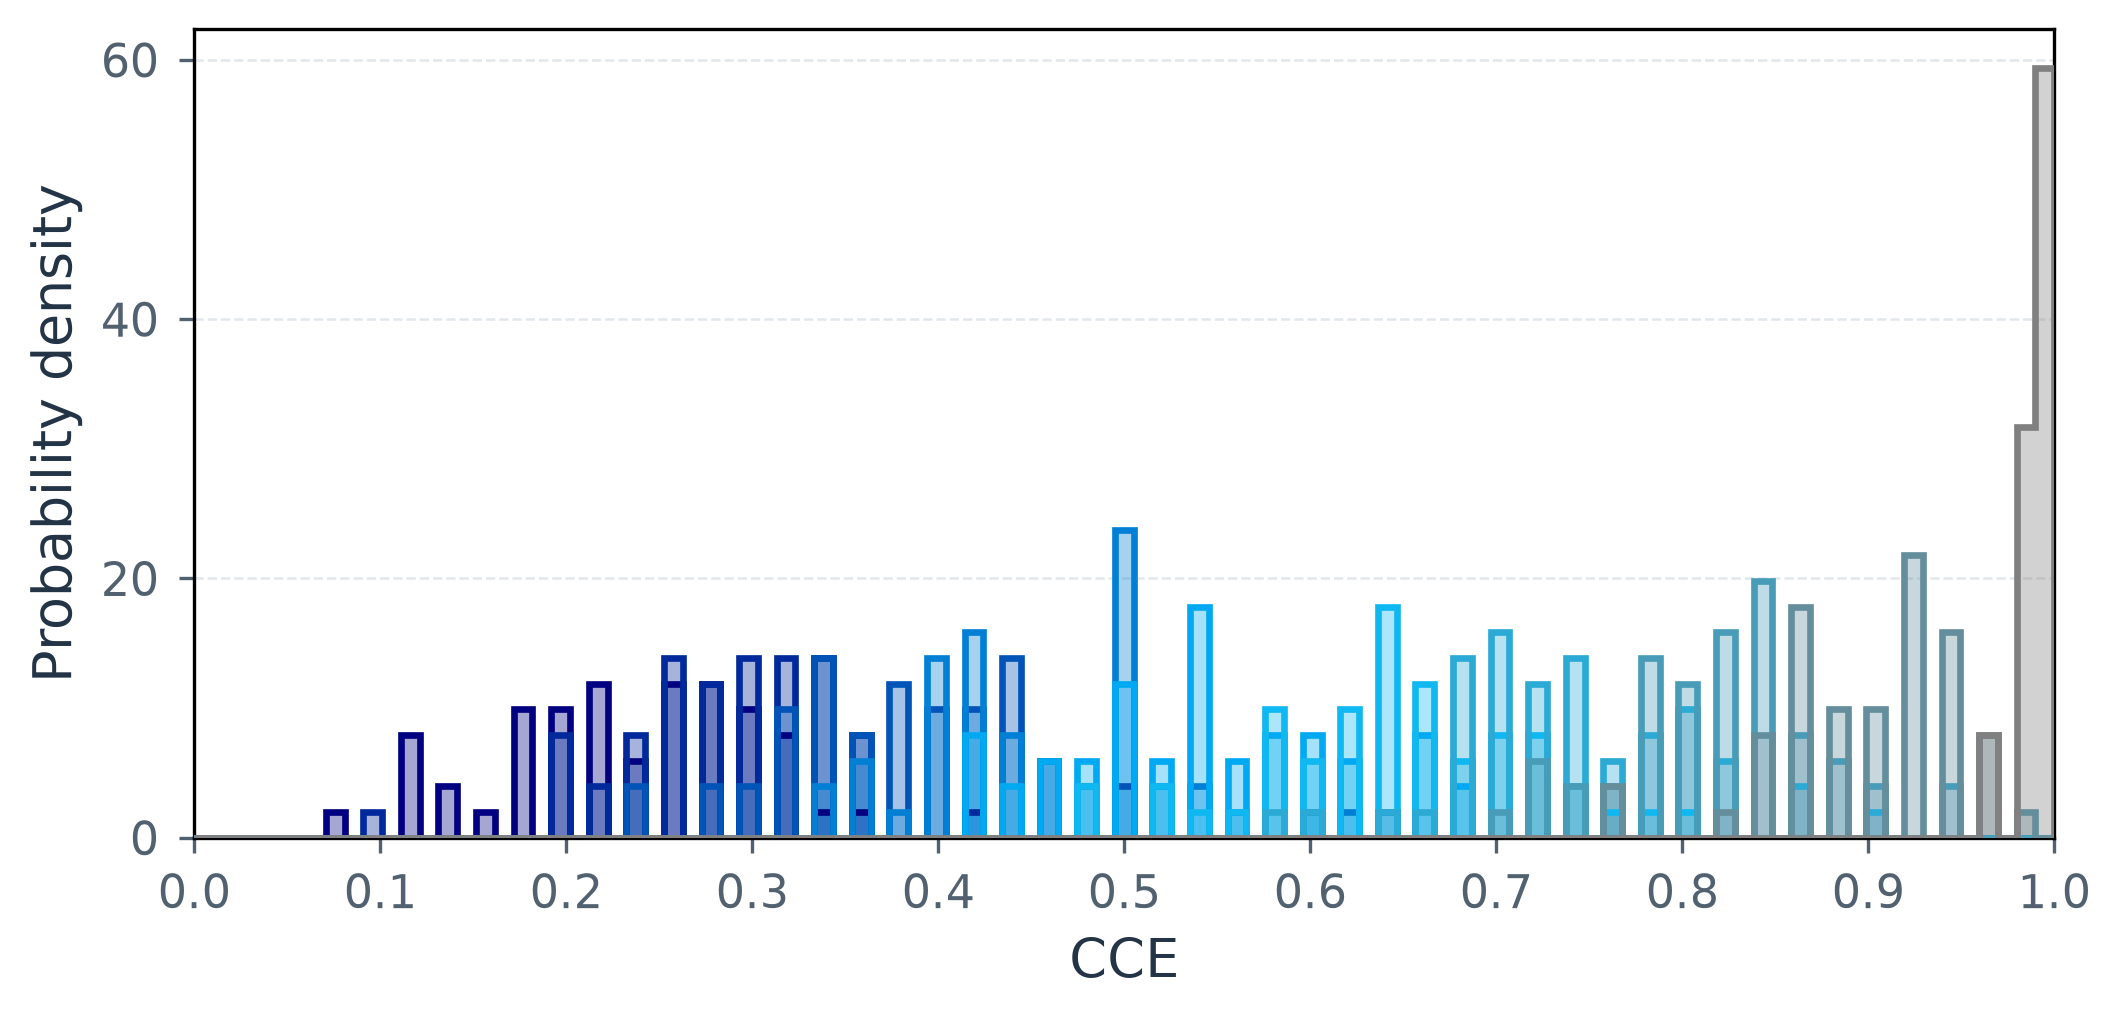

In [36]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D
from pathlib import Path

# ============================================================
# DEPTHS AND COLORS
# ============================================================

depth_indices = np.arange(8, 18, 1)
CCE_width = []

cmap = LinearSegmentedColormap.from_list(
    "presentation",
    ["navy", "deepskyblue", "grey"],
)

colors = cmap(np.linspace(0, 1, len(depth_indices)))

# Stessi bin per tutte le distribuzioni
bins = np.linspace(
    np.min(CCE_matrix),
    np.max(CCE_matrix),
    100,
)

# ============================================================
# FIGURE
# ============================================================

with plt.rc_context({
    "font.family": "sans-serif",
    "font.size": 11,
    "axes.labelsize": 13,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "axes.linewidth": 0.8,
    "text.color": "#243447",
    "axes.labelcolor": "#243447",
    "xtick.color": "#526170",
    "ytick.color": "#526170",
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white",
}):
    fig, ax = plt.subplots(
        figsize=(8, 3.5),
        dpi=300,
    )

    for k, i in enumerate(depth_indices):
        cce_dist = CCE_matrix[i, :]

        # Semidispersione massima
        cce_min = np.min(cce_dist)
        cce_max = np.max(cce_dist)
        semidispersione = (cce_max - cce_min) / 2

        CCE_width.append(semidispersione)

        # Riempimento leggero
        ax.hist(
            cce_dist,
            bins=bins,
            density=True,
            histtype="stepfilled",
            color=colors[k],
            edgecolor="none",
            alpha=0.35,
            zorder=2,
        )

        # Contorno della distribuzione
        ax.hist(
            cce_dist,
            bins=bins,
            density=True,
            histtype="step",
            color=colors[k],
            linewidth=1.6,
            zorder=3,
        )
        '''
        print(
            f"x = {x[i] * 10:.3f} mm"
            f" --> CCE mean = {CCE_mean[i]:.5f}"
            f" --> CCE min = {cce_min:.5f}"
            f" --> CCE max = {cce_max:.5f}"
            f" --> semidispersione = {semidispersione:.5f}"
        )'''

    CCE_width = np.asarray(CCE_width)

    # ========================================================
    # AXES
    # ========================================================

    ax.set(
        xlabel="CCE",
        ylabel="Probability density",
        xlim=(0, 1),
        ylim=(0, None),
    )

    ax.set_xticks(np.arange(0, 1.01, 0.1))
    ax.locator_params(axis="y", nbins=5)

    ax.set_axisbelow(True)
    ax.grid(
        axis="y",
        color="#E2E7EC",
        linewidth=0.6,
        linestyle="--",
    )

    #ax.spines["top"].set_visible(False)
    #ax.spines["right"].set_visible(False)



    ax.tick_params(
        direction="out",
        length=3.5,
        width=0.8,
        #color="#94A3B0",
        pad=5,
    )

    ax.margins(y=0.08)

    # ========================================================
    # LEGEND: FIRST, SECOND, ..., LAST DEPTH
    # ========================================================
    '''
    legend_handles = [
        Line2D([], [], color=colors[0], linewidth=2),
        Line2D([], [], color=colors[1], linewidth=2),
        Line2D([], [], linestyle="none"),
        Line2D([], [], color=colors[-1], linewidth=2),
    ]'''

    legend_labels = [
        f"{x[depth_indices[0]] * 10:.2f} mm",
        f"{x[depth_indices[1]] * 10:.2f} mm",
        r"$\cdots$",
        f"{x[depth_indices[-1]] * 10:.2f} mm",
    ]

    ax.legend(
        legend_handles,
        legend_labels,
        #title="Depth",
        loc="lower center",
        bbox_to_anchor=(0.5, 1.02),
        ncol=4,
        frameon=True,
        fontsize=11,
        title_fontsize=11,
        handlelength=1.8,
        columnspacing=1,
    )

    # ========================================================
    # SAVE AND SHOW
    # ========================================================

    fig.tight_layout()

    Path("plot").mkdir(parents=True, exist_ok=True)

    fig.savefig(
        "plot/CCE_pdf.png",
        dpi=300,
        bbox_inches="tight",
        pad_inches=0.15,
    )

    plt.show()


In [ ]:


# ==========================================
# ARRAY
# ==========================================

CCE_width = np.array(CCE_width)

# profondità corrispondenti
depth = x[depth_indices] * 10


# ==========================================
# GRAFICO SEMIDISPERSIONE
# ==========================================

cmap = plt.colormaps["inferno"]
line_color = cmap(0.65)

plt.figure(figsize=(8, 5))

plt.plot(
    depth,
    CCE_width,
    color=line_color,
    linewidth=2.5,
    marker="o",
    markersize=8,
    markerfacecolor="white",
    markeredgewidth=2,
    markeredgecolor=line_color
)


# ==========================================
# VALORI DELLA MEDIA SOPRA I PUNTI
# ==========================================

for i, (xi, yi) in enumerate(zip(depth, CCE_width)):

    ax.text(
        xi,
        yi * 1.08,
        f"{CCE_mean[depth_indices[i]]:.3f}",
        ha="center",
        va="bottom",
        fontsize=9
    )




plt.xlabel("Depth [mm]", fontsize=13)

plt.ylabel(
    r"Maximum semidispersion $\Delta_{\mathrm{max}}$",
    fontsize=13
)

plt.grid(
    alpha=0.3,
    linestyle="--"
)

plt.tick_params(
    labelsize=11
)

plt.tight_layout()

plt.show()


In [ ]:
CCE_width

<>:129: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
<>:129: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
/tmp/ipykernel_1054111/1462664098.py:129: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
  label=f"Final $\sigma$ = {final_std:.4f}"


Depth = 0.200 mm
Final number of repetitions = 50
Final mean CCE = 0.03560
Final std CCE = 0.02533
Final statistical error = 0.00358


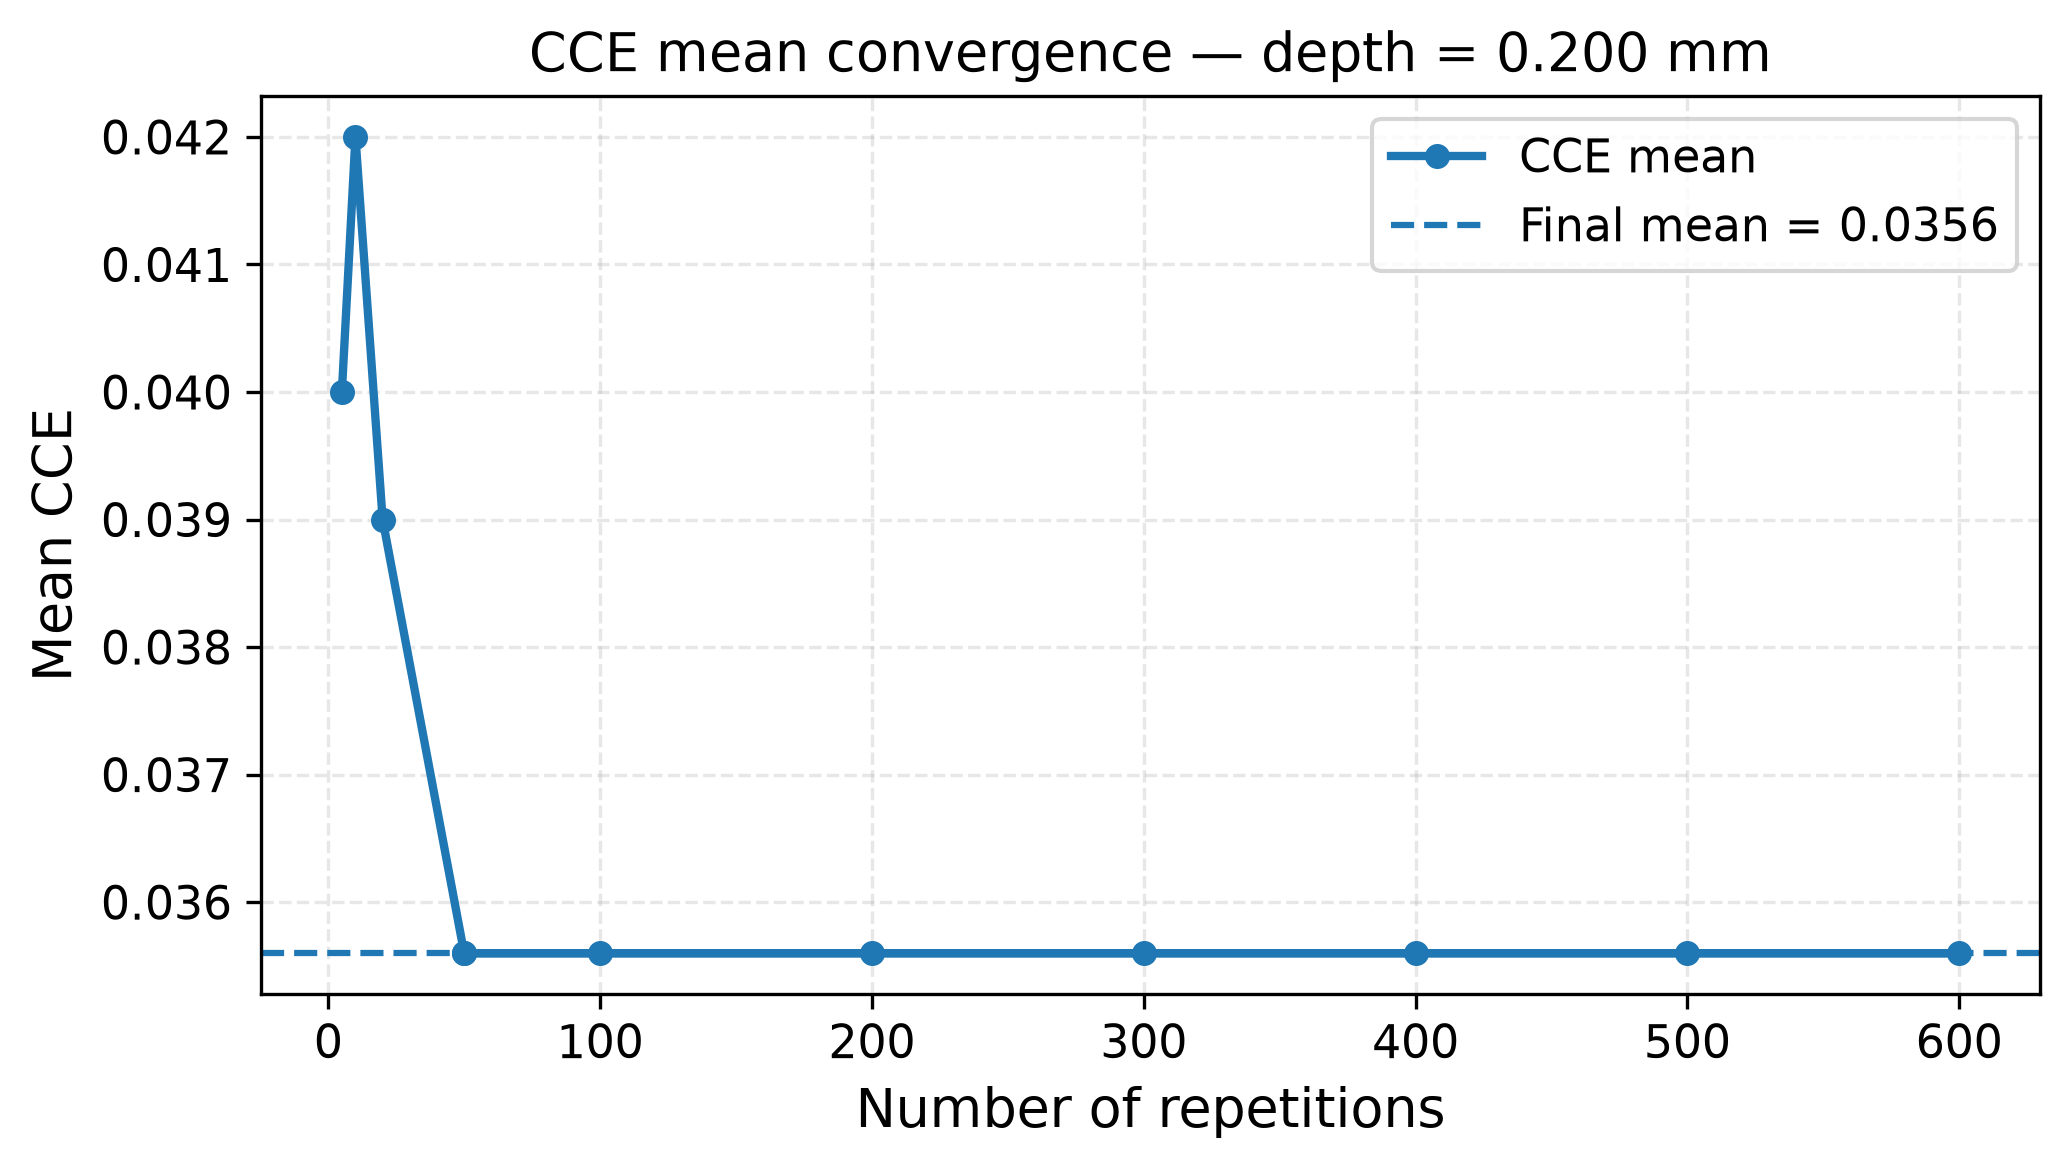

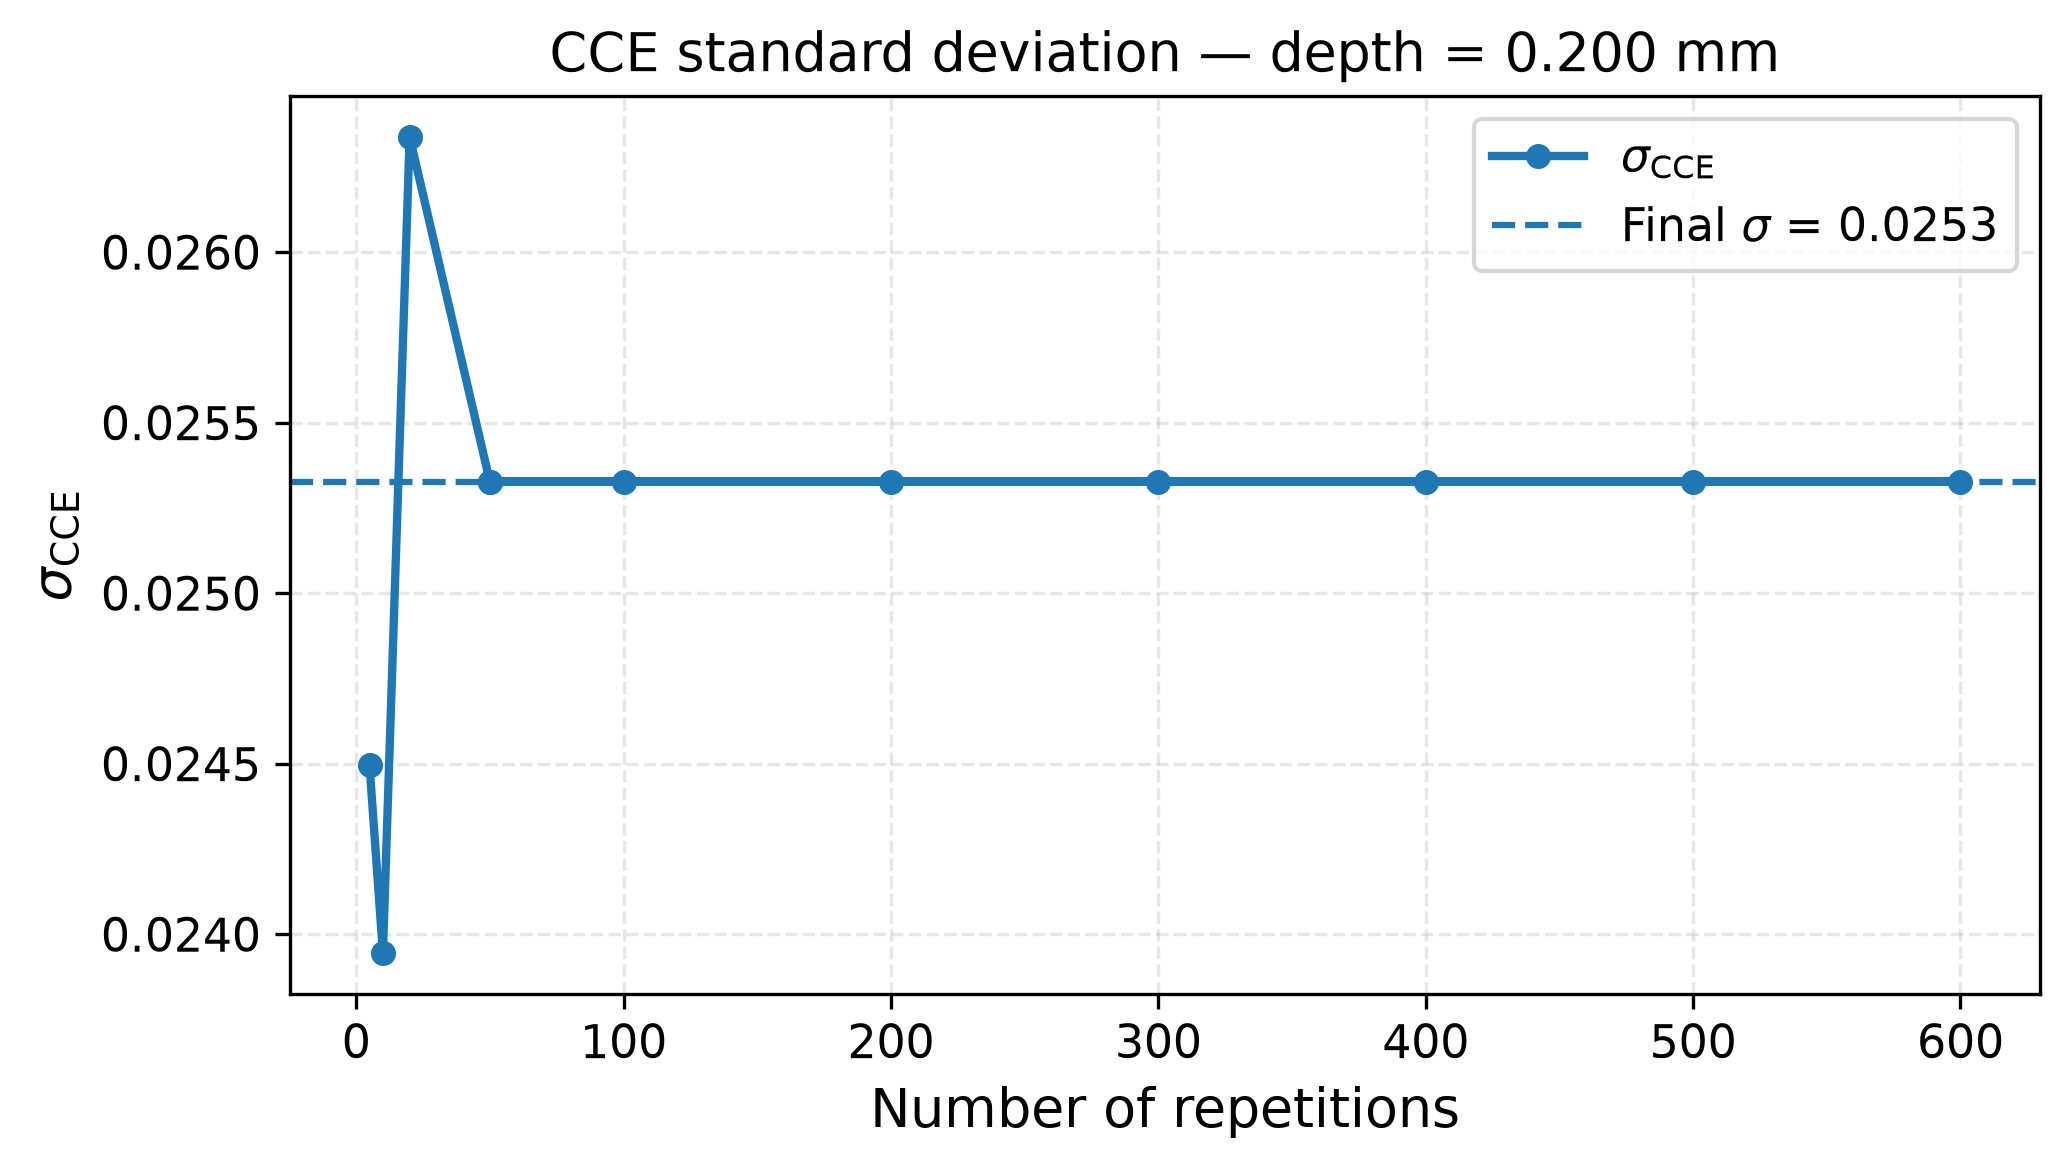

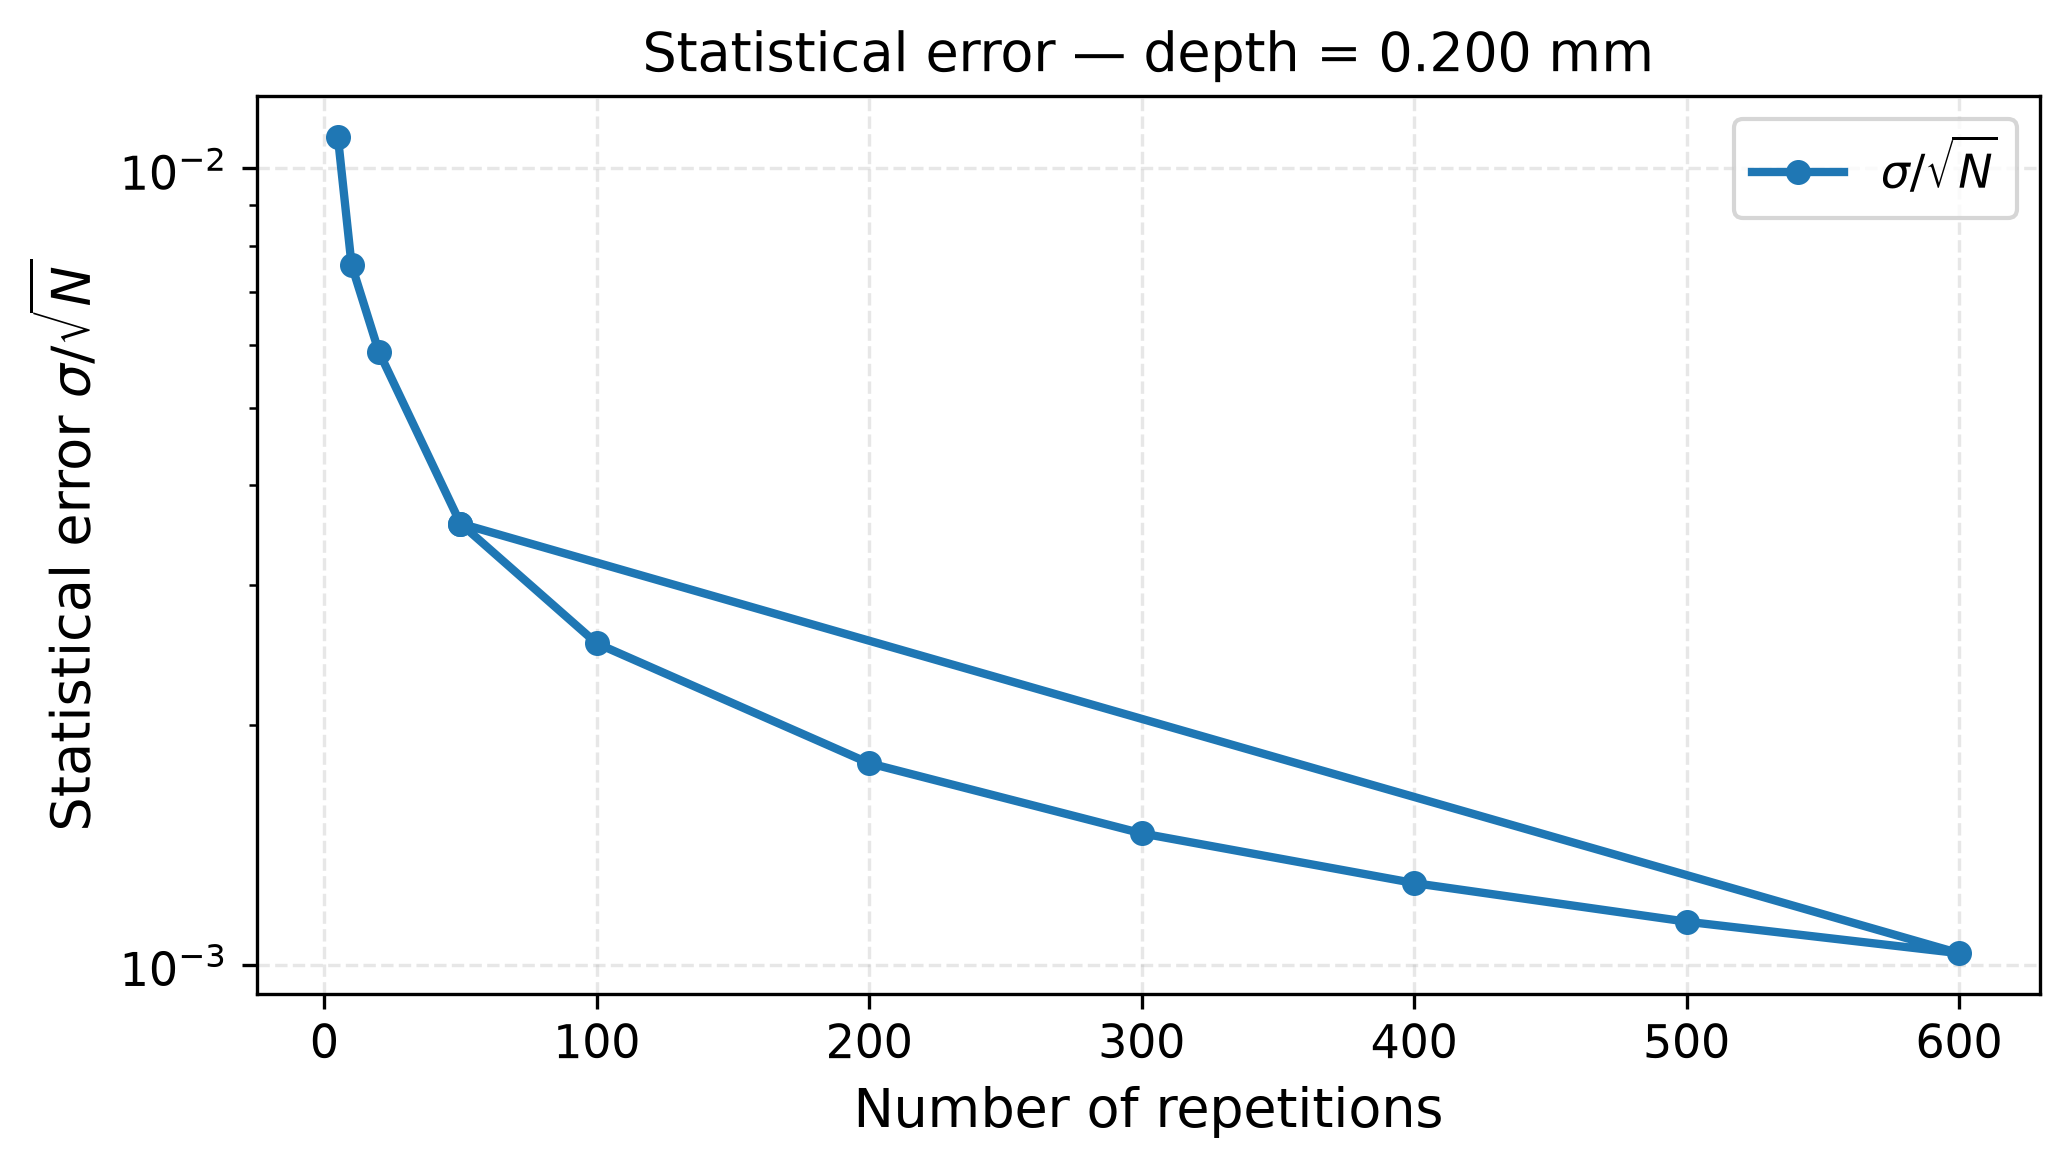

In [37]:
# ==========================================
# PARAMETRI
# ==========================================

N_values = np.array([
    5, 10, 20, 50, 100, 200, 300, 400, 500, 600,
    CCE_matrix.shape[1]
])

# profondità da monitorare
depth_index = 4

# profondità in mm
depth = x[depth_index] * 10


# ==========================================
# CALCOLO
# ==========================================

mean_values = []
std_values = []
std_mean_values = []

for N in N_values:

    # prime N ripetizioni
    data = CCE_matrix[depth_index, :N]

    # media
    mean = np.mean(data)

    # deviazione standard campionaria
    sigma = np.std(data, ddof=1)

    # errore statistico sulla media
    sigma_mean = sigma / np.sqrt(N)

    mean_values.append(mean)
    std_values.append(sigma)
    std_mean_values.append(sigma_mean)


# converto in array
mean_values = np.array(mean_values)
std_values = np.array(std_values)
std_mean_values = np.array(std_mean_values)


# ==========================================
# VALORI FINALI DI RIFERIMENTO
# ==========================================

final_mean = mean_values[-1]
final_std = std_values[-1]
final_std_mean = std_mean_values[-1]

print(f"Depth = {depth:.3f} mm")
print(f"Final number of repetitions = {N_values[-1]}")
print(f"Final mean CCE = {final_mean:.5f}")
print(f"Final std CCE = {final_std:.5f}")
print(f"Final statistical error = {final_std_mean:.5f}")


# ==========================================
# 1. CONVERGENZA DELLA MEDIA
# ==========================================

fig, ax = plt.subplots(figsize=(7, 4), dpi=300)

ax.plot(
    N_values,
    mean_values,
    marker="o",
    linewidth=2,
    markersize=5,
    label="CCE mean"
)

# media finale come riferimento
ax.axhline(
    final_mean,
    linestyle="--",
    linewidth=1.5,
    label=f"Final mean = {final_mean:.4f}"
)

ax.set_xlabel("Number of repetitions", fontsize=13)
ax.set_ylabel("Mean CCE", fontsize=13)

ax.set_title(
    f"CCE mean convergence — depth = {depth:.3f} mm",
    fontsize=13
)

ax.grid(
    alpha=0.3,
    linestyle="--"
)

ax.tick_params(labelsize=11)

ax.legend(fontsize=11)

plt.tight_layout()
plt.show()


# ==========================================
# 2. CONVERGENZA DELLA DEVIAZIONE STANDARD
# ==========================================

fig, ax = plt.subplots(figsize=(7, 4), dpi=300)

ax.plot(
    N_values,
    std_values,
    marker="o",
    linewidth=2,
    markersize=5,
    label=r"$\sigma_{\mathrm{CCE}}$"
)

# deviazione standard finale come riferimento
ax.axhline(
    final_std,
    linestyle="--",
    linewidth=1.5,
    label=f"Final $\sigma$ = {final_std:.4f}"
)

ax.set_xlabel("Number of repetitions", fontsize=13)
ax.set_ylabel(r"$\sigma_{\mathrm{CCE}}$", fontsize=13)

ax.set_title(
    f"CCE standard deviation — depth = {depth:.3f} mm",
    fontsize=13
)

ax.grid(
    alpha=0.3,
    linestyle="--"
)

ax.tick_params(labelsize=11)

ax.legend(fontsize=11)

plt.tight_layout()
plt.show()


# ==========================================
# 3. ERRORE STATISTICO SULLA MEDIA
# ==========================================

fig, ax = plt.subplots(figsize=(7, 4), dpi=300)

ax.plot(
    N_values,
    std_mean_values,
    marker="o",
    linewidth=2,
    markersize=5,
    label=r"$\sigma/\sqrt{N}$"
)

ax.set_xlabel("Number of repetitions", fontsize=13)
ax.set_ylabel(r"Statistical error $\sigma/\sqrt{N}$", fontsize=13)

ax.set_title(
    f"Statistical error — depth = {depth:.3f} mm",
    fontsize=13
)

# scala logaritmica
ax.set_yscale("log")

ax.grid(
    alpha=0.3,
    linestyle="--"
)

ax.tick_params(labelsize=11)

ax.legend(fontsize=11)

plt.tight_layout()
plt.show()

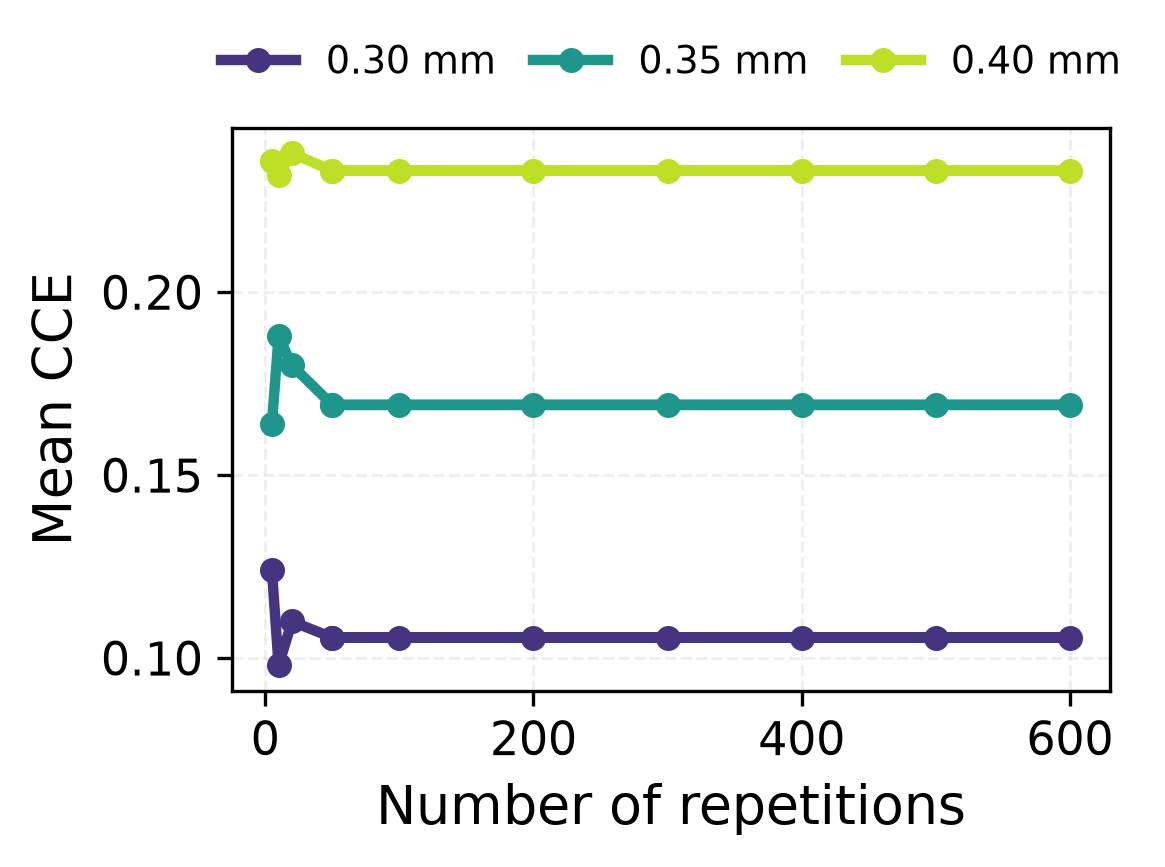

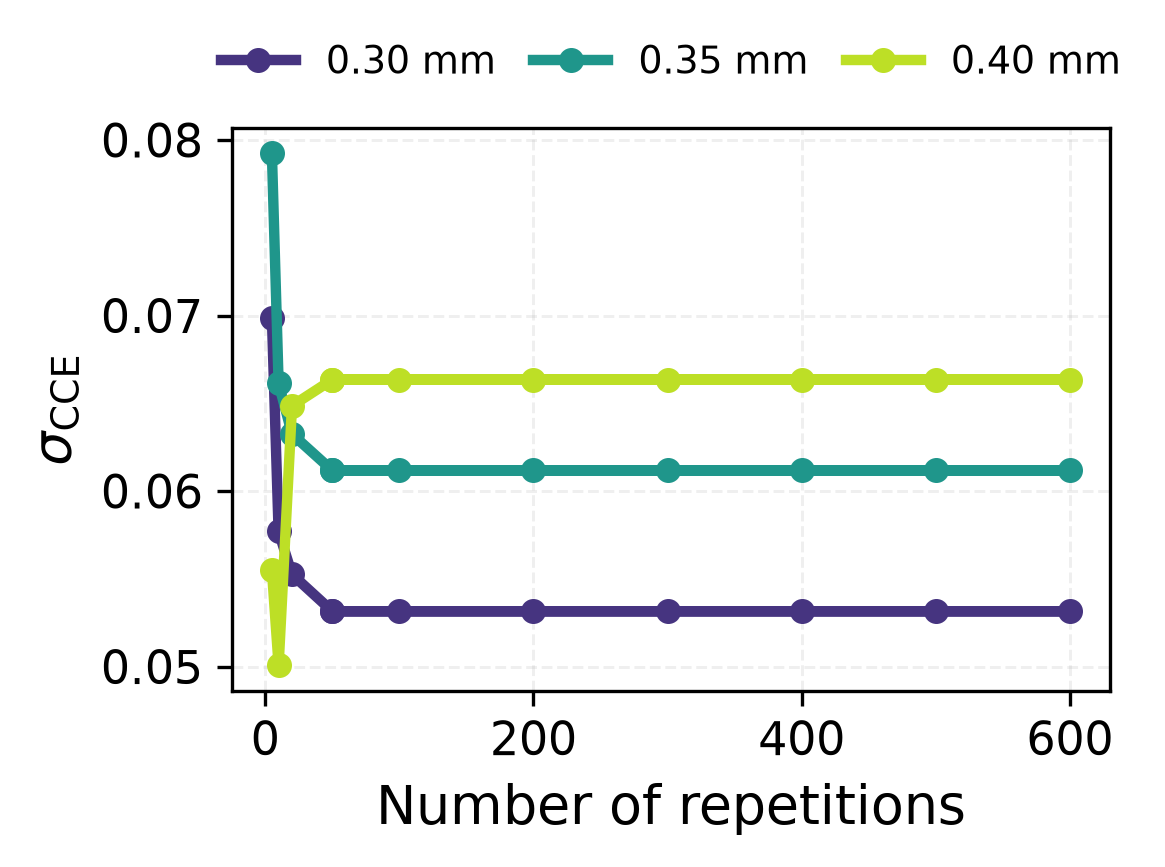

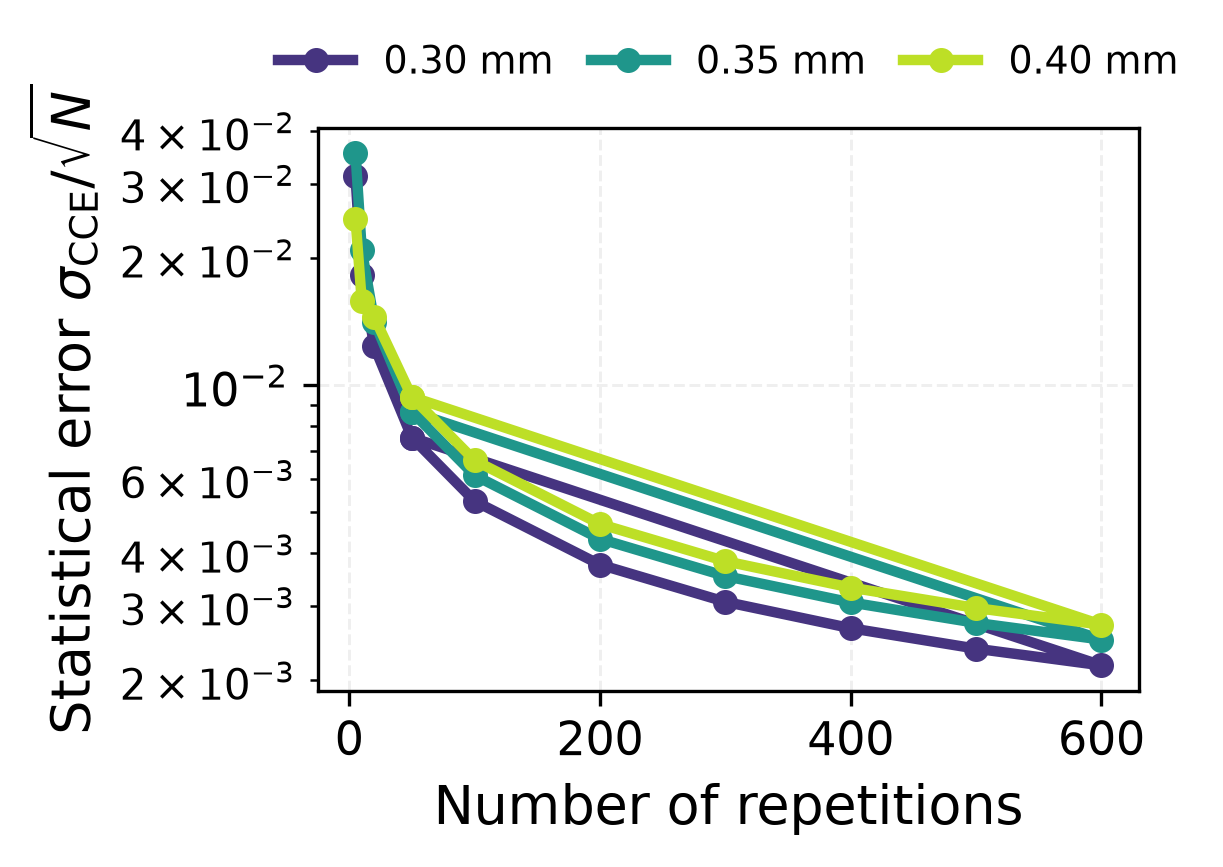

In [38]:
# ============================================================
# PARAMETERS
# ============================================================

N_values = [
    5, 10, 20, 50, 100, 200,
    300, 400, 500, 600,
    CCE_matrix.shape[1]
]

# Depths to compare
depth_indices = [6, 7, 8]


# ============================================================
# COLORS
# ============================================================

colors = plt.colormaps["viridis"](
    np.linspace(
        0.15,
        0.90,
        len(depth_indices)
    )
)


# ============================================================
# CREATE ARRAYS
# ============================================================

mean_all = []
std_all = []
std_mean_all = []


for depth_index in depth_indices:

    mean_values = []
    std_values = []
    std_mean_values = []

    for N in N_values:

        # ----------------------------------------------------
        # First N repetitions
        # ----------------------------------------------------

        data = CCE_matrix[
            depth_index,
            :N
        ]

        # ----------------------------------------------------
        # Mean
        # ----------------------------------------------------

        mean = np.mean(data)

        # ----------------------------------------------------
        # Standard deviation
        # ----------------------------------------------------

        sigma = np.std(
            data,
            ddof=1
        )

        # ----------------------------------------------------
        # Statistical error on the mean
        # ----------------------------------------------------

        sigma_mean = (
            sigma /
            np.sqrt(N)
        )

        mean_values.append(mean)
        std_values.append(sigma)
        std_mean_values.append(sigma_mean)

    mean_all.append(mean_values)
    std_all.append(std_values)
    std_mean_all.append(std_mean_values)


# ============================================================
# CONVERT TO NUMPY ARRAYS
# ============================================================

mean_all = np.array(mean_all)
std_all = np.array(std_all)
std_mean_all = np.array(std_mean_all)


# ============================================================
# DEPTH VALUES
# ============================================================

depths = (
    x[depth_indices] * 10
)


# ============================================================
# 1. CONVERGENCE OF THE MEAN
# ============================================================

fig, ax = plt.subplots(
    figsize=(4, 3),
    dpi=300
)


for k, depth in enumerate(depths):

    ax.plot(
        N_values,
        mean_all[k],
        marker="o",
        markersize=5,
        linewidth=2.5,
        color=colors[k],
        label=f"{depth:.2f} mm"
    )


# ------------------------------------------------------------
# LABELS
# ------------------------------------------------------------

ax.set_xlabel(
    "Number of repetitions",
    fontsize=13
)

ax.set_ylabel(
    "Mean CCE",
    fontsize=13
)




# ------------------------------------------------------------
# TICKS
# ------------------------------------------------------------

ax.tick_params(
    axis="both",
    labelsize=11
)


# ------------------------------------------------------------
# GRID
# ------------------------------------------------------------

ax.grid(
    alpha=0.2,
    linestyle="--",
    linewidth=0.7
)


# ------------------------------------------------------------
# LEGEND
# ------------------------------------------------------------

ax.legend(
    loc="lower center",
    bbox_to_anchor=(0.5, 1.02),
    ncol=3,
    fontsize=9,
    frameon=False,
    columnspacing=1.0
)


# ------------------------------------------------------------
# LAYOUT + SAVE
# ------------------------------------------------------------

fig.tight_layout()

fig.savefig(
    "plot/mean_vs_rep.png",
    dpi=300,
    bbox_inches="tight",
    pad_inches=0.08
)

plt.show()

plt.close(fig)


# ============================================================
# 2. CONVERGENCE OF STANDARD DEVIATION
# ============================================================

fig, ax = plt.subplots(
    figsize=(4, 3),
    dpi=300
)


for k, depth in enumerate(depths):

    ax.plot(
        N_values,
        std_all[k],
        marker="o",
        markersize=5,
        linewidth=2.5,
        color=colors[k],
        label=f"{depth:.2f} mm"
    )


# ------------------------------------------------------------
# LABELS
# ------------------------------------------------------------

ax.set_xlabel(
    "Number of repetitions",
    fontsize=13
)

ax.set_ylabel(
    r"$\sigma_{\mathrm{CCE}}$",
    fontsize=13
)


# ------------------------------------------------------------
# TICKS
# ------------------------------------------------------------

ax.tick_params(
    axis="both",
    labelsize=11
)


# ------------------------------------------------------------
# GRID
# ------------------------------------------------------------

ax.grid(
    alpha=0.2,
    linestyle="--",
    linewidth=0.7
)



# ------------------------------------------------------------
# LEGEND
# ------------------------------------------------------------

ax.legend(
    loc="lower center",
    bbox_to_anchor=(0.5, 1.02),
    ncol=3,
    fontsize=9,
    frameon=False,
    columnspacing=1.0
)


# ------------------------------------------------------------
# LAYOUT + SAVE
# ------------------------------------------------------------

fig.tight_layout()

fig.savefig(
    "plot/sigma_vs_rep.png",
    dpi=300,
    bbox_inches="tight",
    pad_inches=0.08
)

plt.show()

plt.close(fig)


# ============================================================
# 3. STATISTICAL ERROR ON THE MEAN
# ============================================================

fig, ax = plt.subplots(
    figsize=(4, 3),
    dpi=300
)


for k, depth in enumerate(depths):

    ax.plot(
        N_values,
        std_mean_all[k],
        marker="o",
        markersize=5,
        linewidth=2.5,
        color=colors[k],
        label=f"{depth:.2f} mm"
    )


# ------------------------------------------------------------
# LABELS
# ------------------------------------------------------------

ax.set_xlabel(
    "Number of repetitions",
    fontsize=13
)

ax.set_ylabel(
    r"Statistical error $\sigma_{\mathrm{CCE}}/\sqrt{N}$",
    fontsize=13
)


# ------------------------------------------------------------
# LOG SCALE
# ------------------------------------------------------------

ax.set_yscale(
    "log"
)


# ------------------------------------------------------------
# TICKS
# ------------------------------------------------------------

ax.tick_params(
    axis="both",
    labelsize=11
)


# ------------------------------------------------------------
# GRID
# ------------------------------------------------------------

ax.grid(
    axis="both",
    alpha=0.2,
    linestyle="--",
    linewidth=0.7
)


# ------------------------------------------------------------
# LEGEND
# ------------------------------------------------------------

ax.legend(
    loc="lower center",
    bbox_to_anchor=(0.5, 1.02),
    ncol=3,
    fontsize=9,
    frameon=False,
    columnspacing=1.0
)


# ------------------------------------------------------------
# LAYOUT + SAVE
# ------------------------------------------------------------

fig.tight_layout()

fig.savefig(
    "plot/mean_error.png",
    dpi=300,
    bbox_inches="tight",
    pad_inches=0.08
)

plt.show()

plt.close(fig)

In [39]:
import numpy as np
import matplotlib.pyplot as plt


# ============================================================
# PARAMETRI
# ============================================================

# numero di ripetizioni da testare
N_values = [
    5, 10, 20, 50, 100,
    200, 500, 2500, 4000,
    CCE_matrix.shape[1]
]

# profondità da analizzare
depth_index = 8


# array risultati
mean_values = []
std_values = []
std_mean_values = []
range_values = []


# ============================================================
# CALCOLO STATISTICHE
# ============================================================

for N in N_values:

    # prime N simulazioni
    data = CCE_matrix[depth_index, :N]

    # media
    mean = np.mean(data)

    # deviazione standard
    sigma = np.std(data)

    # errore sulla media
    sigma_mean = sigma / np.sqrt(N)

    # massima dispersione
    dispersion = np.max(data) - np.min(data)


    mean_values.append(mean)
    std_values.append(sigma)
    std_mean_values.append(sigma_mean)
    range_values.append(dispersion)




In [40]:

# conversione array
mean_values = np.array(mean_values)
std_values = np.array(std_values)
std_mean_values = np.array(std_mean_values)
range_values = np.array(range_values)




In [41]:

# valori finali con tutte le simulazioni
mean_ref = np.mean(CCE_matrix[depth_index])
sigma_ref = np.std(CCE_matrix[depth_index])

range_ref = (
    np.max(CCE_matrix[depth_index])
    -
    np.min(CCE_matrix[depth_index])
)



# stile
color = plt.colormaps["inferno"](0.65)


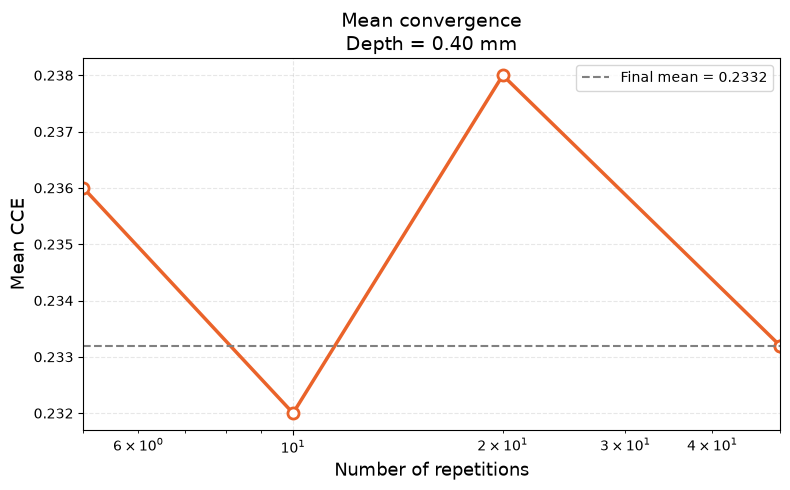

In [42]:
# ============================================================
# 1) CONVERGENZA DELLA MEDIA
# ============================================================

plt.figure(figsize=(8,5))

plt.plot(
    N_values,
    mean_values,
    "-o",
    color=color,
    linewidth=2.5,
    markersize=8,
    markerfacecolor="white",
    markeredgewidth=2
)

plt.axhline(
    mean_ref,
    color="gray",
    linestyle="--",
    linewidth=1.5,
    label=f"Final mean = {mean_ref:.4f}"
)

# scala logaritmica
plt.xscale("log")

# asse X da 5 fino a 500
plt.xlim(
    N_values[0],
    CCE_matrix.shape[1]
)

plt.xlabel(
    "Number of repetitions",
    fontsize=13
)

plt.ylabel(
    "Mean CCE",
    fontsize=13
)

plt.title(
    f"Mean convergence\nDepth = {x[depth_index]*10:.2f} mm",
    fontsize=14
)

plt.grid(
    alpha=0.3,
    linestyle="--"
)

plt.legend()

plt.tight_layout()

plt.show()

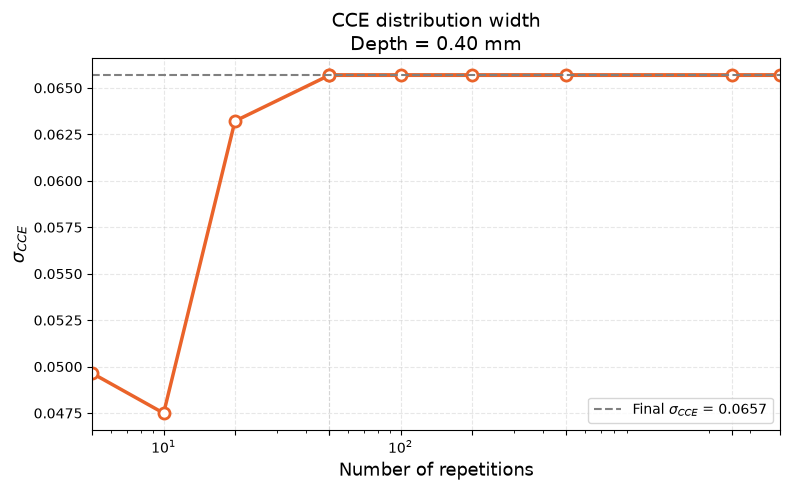

In [43]:
# ============================================================
# 2) CONVERGENZA DELLA DISTRIBUZIONE
# ============================================================

plt.figure(figsize=(8,5))

plt.plot(
    N_values,
    std_values,
    "-o",
    color=color,
    linewidth=2.5,
    markersize=8,
    markerfacecolor="white",
    markeredgewidth=2
)

plt.axhline(
    sigma_ref,
    color="gray",
    linestyle="--",
    linewidth=1.5,
    label=fr"Final $\sigma_{{CCE}}$ = {sigma_ref:.4f}"
)

# scala logaritmica
plt.xscale("log")

# asse X fino al numero totale di ripetizioni
plt.xlim(
    N_values[0],
    CCE_matrix.shape[1]
)

# tick dell'asse X
plt.xticks(
    N_values
)

plt.xlabel(
    "Number of repetitions",
    fontsize=13
)

plt.ylabel(
    r"$\sigma_{CCE}$",
    fontsize=13
)

plt.title(
    f"CCE distribution width\nDepth = {x[depth_index]*10:.2f} mm",
    fontsize=14
)

plt.grid(
    alpha=0.3,
    linestyle="--"
)

plt.legend()

plt.tight_layout()

plt.show()

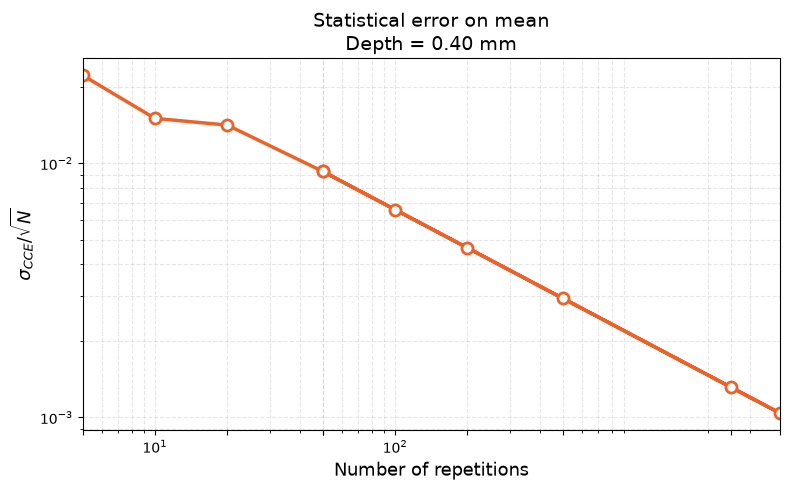

In [44]:
# ============================================================
# 3) ERRORE STATISTICO SULLA MEDIA
# ============================================================

plt.figure(figsize=(8,5))

plt.plot(
    N_values,
    std_mean_values,
    "-o",
    color=color,
    linewidth=2.5,
    markersize=8,
    markerfacecolor="white",
    markeredgewidth=2
)

plt.xscale("log")
plt.yscale("log")

# asse X fino a 500
plt.xlim(
    N_values[0],
    CCE_matrix.shape[1]
)

# tick dell'asse X
plt.xticks(
    N_values
)

plt.xlabel(
    "Number of repetitions",
    fontsize=13
)

plt.ylabel(
    r"$\sigma_{CCE}/\sqrt{N}$",
    fontsize=13
)

plt.title(
    f"Statistical error on mean\nDepth = {x[depth_index]*10:.2f} mm",
    fontsize=14
)

plt.grid(
    alpha=0.3,
    linestyle="--",
    which="both"
)

plt.tight_layout()

plt.show()